<span style="font-size: 50px;">Documentation & Tutorial For TelumMPS</span>

<span style="font-size: 20px;">
This is Documantation & Tutorial for TelumMPS.jl which tools for many algorithm related with MPS (in many body theory) based on Telum.jl 
<br>
Most of MPS based algorithm is (will be) supported and some of not MPS_based algorithm (ex. XTRG) is also supported

</span>

In [1]:
using AppleAccelerate # if you are on macos!
using LurCGT, Telum, LinearAlgebra, Serialization
include("src/TelumMPS.jl")
using .TelumMPS
using Plots
default(
    dpi=300, fontfamily="Computer Modern", framestyle=:box,
    grid=true, gridalpha=0.3, linewidth=1.5, markersize=5,
    tickfontsize=10, guidefontsize=12, titlefontsize=13,
    legendfontsize=9)

┌ Warning: MKL is not available/installed.
└ @ MKL ~/.julia/packages/MKL/JVoAz/src/MKL.jl:39


<span style="font-size: 20px"> 

# 1.Constructing MPO & initial MPS

<span style="font-size: 20px"> 

## 1.1 Constructing MPO

<span style="font-size: 20px"> 

### 1.1.1 from single MPO block


<span style="font-size: 20px;">
in general, hamiltonian ,that we are interested in, can be constructed from a single MPO block.
for example, the hamiltonian of spin-orbit model (which comes from the tutorial material of Telum.jl) can be written as 


$$
\begin{align}

H =  \sum_{i} \left( \vec{S}_i \cdot \vec{S}_{i+1} + \frac{1}{2} \vec{S}_i \cdot \vec{S}_{i+2} \right)
\end{align}
$$

and its MPO-block is like 
$$

\begin{align}
    W_{i}=
    \begin{pmatrix}
        I_{S=0} & 0 & 0 & 0  \\
        S^{\dagger} & 0 & 0 & 0  \\
        0 & I_{S=1} & 0 & 0  \\
        0 & S & \frac{1}{2}S & I_{S=0}  \\
    \end{pmatrix}
\end{align}
$$

the Hamiltonian can be constructed as a sequence of this MPO block 
and, for the most case, the first and last of MPO block can be acquired from

MPO[end,:] and MPO[:,1]

by using this property, we can get full MPO blocks by defining a single block.

let's see the example

</span>


In [2]:
option = SpinOptions(:SU2,1)
gls = getLocalSpace(option,("site","site","op")) 

(I = 2D TLArray, 1 symmetries [SU2]  ["site+", "site-"]
  1.	1x1	| 2x2	[ 1 ; 1 ]	1.000000	√2, S = 3D TLArray, 1 symmetries [SU2]  ["site+", "site-", "op-"]
  1.	1x1x1	| 2x2x3	[ 1 ; 1 ; 2 ]	1.224745)

<span style="font-size: 20px;">
it is just repeat from tutorial of Telum.jl
<br>
(constructing single MPO block (tensor))
</span>

In [3]:
Wi_mat = Matrix{TLArray}(undef, 4, 4)
i4d = addSingleton(gls.I, (3, 4); itag=("left", "right"), dir=('+', '-'))
s4d = addSingleton(gls.S, 3; itag="left", dir='+')
s4d = setitag(s4d, 4, "right")
sc4d = addSingleton(gls.S', 4; itag="right", dir='-')
sc4d = permutedims(setitag(sc4d, 3, "left"), (2, 1, 3, 4))
Wi_mat[1,1] = Wi_mat[4,4] = i4d
Wi_mat[4,2] = s4d
Wi_mat[4,3] = 1/2 * s4d
Wi_mat[2,1] = sc4d
id_S1 = getIdentity((gls.S, 3))
id_S1 = TLArray(id_S1, ("left", "right"))
Wi_mat[3,2] = gls.I ⊗ id_S1

Wi = oplus(Wi_mat,(3,4))

4D TLArray, 1 symmetries [SU2]  ["site+", "site-", "left+", "right-"]
  1.	1x1x2x2	| 2x2x1x1	[ 1 ; 1 ; 0 ; 0 ]
  2.	1x1x2x2	| 2x2x1x3	[ 1 ; 1 ; 0 ; 2 ]
  3.	1x1x2x2	| 2x2x3x1	[ 1 ; 1 ; 2 ; 0 ]
  4.	1x1x2x2	| 2x2x3x3	[ 1 ; 1 ; 2 ; 2 ]

<span style="font-size: 20px">
 After that, we can construct full MPO by using 

In [4]:
N = 40
MPO1 = TLMpo(Wi,N)

TLMpo (L=40)
  canonical center: none
  symmetry: SU2  (1 symmetry)
  max bond dim (reduced): 4
 i,tag (D(*)|#of sectors): 

  [ 1] 1,site+ (1|1s)  1,site- (1|1s)  dummy_l+ (1|1s)  1,bond,w- (4|2s)
  [ 2] 2,site+ (1|1s)  2,site- (1|1s)  1,bond,w+ (4|2s)  2,bond,w- (4|2s)
  [ 3] 3,site+ (1|1s)  3,site- (1|1s)  2,bond,w+ (4|2s)  3,bond,w- (4|2s)
  [ 4] 4,site+ (1|1s)  4,site- (1|1s)  3,bond,w+ (4|2s)  4,bond,w- (4|2s)
  ⋮
  [37] 37,site+ (1|1s)  37,site- (1|1s)  36,bond,w+ (4|2s)  37,bond,w- (4|2s)
  [38] 38,site+ (1|1s)  38,site- (1|1s)  37,bond,w+ (4|2s)  38,bond,w- (4|2s)
  [39] 39,site+ (1|1s)  39,site- (1|1s)  38,bond,w+ (4|2s)  39,bond,w- (4|2s)
  [40] 40,site+ (1|1s)  40,site- (1|1s)  39,bond,w+ (4|2s)  dummy_r- (1|1s)


<span style="font-size: 20px">

now we get the TLMPO
<br>
 i.e.) if we have mpo block for obvious hamiltonain , then we can construct MPO easily

<span style="font-size: 20px"> 

### 1.1.2 from Auto MPO

<span style="font-size: 20px">
but it is not easy for constructing complicated hamiltonian;
<br>
(espacially who doesn't familiar to Non-Abelian Tensor Network)
<br>
<br>

in this case we can use Auto MPO:
<br>
which construct MPO blocks automatically from users inituitive inputs
<br>
it starts by defining autoMPO object
</span>

In [5]:
terms_k = MPOTerm[] 
for i in 1:N-2
    push!(terms_k, term(1.0, i => s4d, i+1 => sc4d)) 
    push!(terms_k, term(0.5, i => s4d, i+2 => sc4d))
end
push!(terms_k, term(1.0, N-1 => s4d, N => sc4d))

MPO2 = auto_mpo(terms_k, N, i4d)

#There's canonical site (it is because of the way to construct AutoMPO)
# -> construct Naively, then truncate zero singular value (same as ITensorMPS or changkai's autoMPO)
# it doesn't affect the result of DMRG (for the most cases)

TLMpo (L=40)
  canonical center: 1
  symmetry: SU2  (1 symmetry)
  max bond dim (reduced): 4
 i,tag (D(*)|#of sectors): 

  [ 1] 1,site+ (1|1s)  1,site- (1|1s)  dummy_l+ (1|1s)  1,bond,w+ (2|2s)  ← oc
  [ 2] 1,bond,w- (2|2s)  2,site+ (1|1s)  2,site- (1|1s)  2,bond,w+ (4|2s)
  [ 3] 2,bond,w- (4|2s)  3,site+ (1|1s)  3,site- (1|1s)  3,bond,w+ (4|2s)
  [ 4] 3,bond,w- (4|2s)  4,site+ (1|1s)  4,site- (1|1s)  4,bond,w+ (4|2s)
  ⋮
  [37] 36,bond,w- (4|2s)  37,site+ (1|1s)  37,site- (1|1s)  37,bond,w+ (4|2s)
  [38] 37,bond,w- (4|2s)  38,site+ (1|1s)  38,site- (1|1s)  38,bond,w+ (4|2s)
  [39] 38,bond,w- (4|2s)  39,site+ (1|1s)  39,site- (1|1s)  39,bond,w+ (2|2s)
  [40] 39,bond,w- (2|2s)  40,site+ (1|1s)  40,site- (1|1s)  dummy_r- (1|1s)


<span style="font-size: 20px"> 

### 1.1.3 Constructing MPO in passive way

<span style="font-size: 20px">
it is just same as tutorial in telum_tutorial but we wrap it as TLMpo object

</span>

In [6]:
zq = zero_qlabels(Wi)

MPO_arr = Vector{TLArray{Float64, 4}}(undef,N)

for i in 1:N
    tags = ("$(i),site","$(i),site", i>1 ? "$(i-1),bond,w" : "dummy_l", i<N ? "$(i),bond,w" : "dummy_r")

    
    if i == 1 MPO_arr[i] = TLArray(getsub(Wi, 3, x -> x== zq ? -1 : nothing), tags)
    elseif i == N MPO_arr[i] = TLArray(getsub(Wi, 4, x->x== zq ? -1 : nothing),tags)
    else MPO_arr[i] = TLArray(Wi, tags) end
    
end
MPO3 = TLMpo(MPO_arr)

TLMpo (L=40)
  canonical center: none
  symmetry: SU2  (1 symmetry)
  max bond dim (reduced): 4
 i,tag (D(*)|#of sectors): 

  [ 1] 1,site+ (1|1s)  1,site- (1|1s)  dummy_l+ (1|1s)  1,bond,w- (4|2s)
  [ 2] 2,site+ (1|1s)  2,site- (1|1s)  1,bond,w+ (4|2s)  2,bond,w- (4|2s)
  [ 3] 3,site+ (1|1s)  3,site- (1|1s)  2,bond,w+ (4|2s)  3,bond,w- (4|2s)
  [ 4] 4,site+ (1|1s)  4,site- (1|1s)  3,bond,w+ (4|2s)  4,bond,w- (4|2s)
  ⋮
  [37] 37,site+ (1|1s)  37,site- (1|1s)  36,bond,w+ (4|2s)  37,bond,w- (4|2s)
  [38] 38,site+ (1|1s)  38,site- (1|1s)  37,bond,w+ (4|2s)  38,bond,w- (4|2s)
  [39] 39,site+ (1|1s)  39,site- (1|1s)  38,bond,w+ (4|2s)  39,bond,w- (4|2s)
  [40] 40,site+ (1|1s)  40,site- (1|1s)  39,bond,w+ (4|2s)  dummy_r- (1|1s)


<span style="font-size: 20px"> 

## 1.2 Initial MPS from iterative diagonalization

cf) the name should be adjusted!!! (improper name)

<span style="font-size: 20px">

### 1.2.1 Grand Canonical Method

<span style="font-size: 20px"> 
the first way to take initial MPS is Grand Canonical Ensemble (GCE) method. 
<br>
which is just same algorithm from tutorial of telum.

the reason for name is ;
it changes their quantum number by taking lowest energy (think about fermion model, the # of electron can be changed from here)

the simple algorithm can be refered below
</span>

In [7]:
Nkeep_init = 10

@show mps1_init, e1_init, sp1_init = init_MPS(MPO1, Nkeep_init) #MPS construction
@show mps2_init, e2_init, sp2_init = init_MPS(MPO1, Nkeep_init) #MPS construction
@show mps3_init, e3_init, sp3_init = init_MPS(MPO1, Nkeep_init) #MPS construction

(mps1_init, e1_init, sp1_init) = init_MPS(MPO1, Nkeep_init) = (TLMps(length=40), -14.998177543351575, ((0,),))
(mps2_init, e2_init, sp2_init) = init_MPS(MPO1, Nkeep_init) = (TLMps(length=40), -14.998177543351575, ((0,),))
(mps3_init, e3_init, sp3_init) = init_MPS(MPO1, Nkeep_init) = (TLMps(length=40), -14.998177543351575, ((0,),))


(TLMps(length=40), -14.998177543351575, ((0,),))

In [8]:
@show mps1_init, e1_init, sp1_init = init_MPS(MPO1, Nkeep_init) #MPS construction


(mps1_init, e1_init, sp1_init) = init_MPS(MPO1, Nkeep_init) = (TLMps(length=40), -14.998177543351575, ((0,),))


(TLMps(length=40), -14.998177543351575, ((0,),))

### 1.2.2 Canonical Method

<span style="font-size: 20px">
the second way is Canonical Ensemble

it is mere to set Canonical Ensemble for spin model 
<br>

but for fermionic model it can be useful (there's no need to set $\mu$)

it can be used by setting initial QN
</span>

In [9]:
Totspin = (((0,),))
println("Given target spin: ", Totspin)
@show mps_init_ce, e_init_ce, sp_init_ce = init_MPS(MPO1, Nkeep_init; target=Totspin) #MPS construction


Totspin = (((2,),))
println("Given target spin: ", Totspin)
@show mps_init_ce, e_init_ce, sp_init_ce = init_MPS(MPO1, Nkeep_init; target=Totspin) #MPS construction

Totspin = (((4,),))
println("Given target spin: ", Totspin)
@show mps_init_ce, e_init_ce, sp_init_ce = init_MPS(MPO1, Nkeep_init; target=Totspin) #MPS construction



# the GCE takes Totspin -> 0 by discarding high energy state

Given target spin: ((0,),)
(mps_init_ce, e_init_ce, sp_init_ce) = init_MPS(MPO1, Nkeep_init; target = Totspin) = (TLMps(length=40), -14.998177543351575, ((0,),))
Given target spin: ((2,),)
(mps_init_ce, e_init_ce, sp_init_ce) = init_MPS(MPO1, Nkeep_init; target = Totspin) = (TLMps(length=40), -14.597541596681168, ((2,),))
Given target spin: ((4,),)
(mps_init_ce, e_init_ce, sp_init_ce) = init_MPS(MPO1, Nkeep_init; target = Totspin) = (TLMps(length=40), -13.597540314285197, ((4,),))


(TLMps(length=40), -13.597540314285197, ((4,),))

<span style="font-size: 20px">
TO get random MPS from with wanted quantum number, we can use
<span>

In [10]:
Totspin = (((40,),))
mps_sector = init_MPS_sector(MPO1, Totspin)

TLMps (L=40)|  center : 40
  symmetry: SU2  (1 symmetry)
  max bond dim (reduced): 1

 i,tag (D(*)|#of sectors): 1
  [ 1] SLeft+ (1|1s)  1,site+ (1|1s)  1,bond,m- (1|1s)
  [ 2] 1,bond,m+ (1|1s)  2,site+ (1|1s)  2,bond,m- (1|1s)
  [ 3] 2,bond,m+ (1|1s)  3,site+ (1|1s)  3,bond,m- (1|1s)
  [ 4] 3,bond,m+ (1|1s)  4,site+ (1|1s)  4,bond,m- (1|1s)
  ⋮
  [37] 36,bond,m+ (1|1s)  37,site+ (1|1s)  37,bond,m- (1|1s)
  [38] 37,bond,m+ (1|1s)  38,site+ (1|1s)  38,bond,m- (1|1s)
  [39] 38,bond,m+ (1|1s)  39,site+ (1|1s)  39,bond,m- (1|1s)
  [40] 39,bond,m+ (1|1s)  40,site+ (1|1s)  dummy_r- (1|1s)  ← oc


<span style="font-size: 20px">

# 2. DMRG & MPS analysis

<span style="font-size: 20px">

## 2.A DMRG routine and option 

<span style="font-size: 20px">

it's time to get ground state. 

now we have all of ingredents. Let's see the examples & various option for DMRG algorithm

the naive way to use dmrg is to start with  the initial state & MPO with maximal bonddimension & number of sweeps

than it start with 2-site DMRG with no discarded weight cutoff & nKrylov = 5
</span>

In [11]:
nsweeps = 10
maxdim = 100
MPS1, E1 = dmrg(mps1_init, MPO1, maxdim, nsweeps,)

╔═════════════════════════════════════════════════════════════════
║  DMRG   ·   mode = 2s    ·   N = 40
║  2026-11-01 (Sunday)  13:25:24
╟─────────────────────────────────────────────────────────────────
║  init_energy = -14.9981775434
║  Nkeep = 100     cutoff (discarded weight) = 0.0e+00
║  Lanczos: nKrylov = 5, tol = 1.0e-08
║  Nsweep = 10     convergence |dE| < 0.0e+00
╚═════════════════════════════════════════════════════════════════
  ┌ sweep  1/10                             [13:25:50]
  │  E = -15.0000000000      dE = -Inf
  │  χ* = 32 (χ = 98)  dw = 6.66e-16      t 25.33s · elapsed 25.4s · ETA 228.5s
  └
  ┌ sweep  2/10                             [13:25:51]
  │  E = -15.0000000000      dE = -8.153e-13
  │  χ* = 100 (χ = 348)  dw = 0.00e+00      t 0.60s · elapsed 26.2s · ETA 105.0s
  └
  ┌ sweep  3/10                             [13:25:51]
  │  E = -15.0000000000      dE = +1.066e-14
  │  χ* = 100 (χ = 338)  dw = 0.00e+00      t 0.48s · elapsed 26.7s · ETA 62.3s
  └
  ┌ sweep

(TLMps(length=40), -14.99999999999999)

<span style="font-size: 20px">

The output shows various information, and we can infer the options.

Below is a list of the options and their descriptions.

1. <span style="color:blue">**mode**</span>
<br>
     <span style="color:green">*option*</span>: <span style="color:orange">"1s"</span>, <span style="color:orange">"2s"</span>, <span style="color:orange">"1s+"</span>
<br>
    <span style="color:green">*description*</span>: 1s & 2s $\rightarrow$ 1s & 2s DMRG update algorithms, and 1s+ means a single-site update with subspace expansion.


2. <span style="color:blue">**cutoff**</span>
<br>
    <span style="color:green">*option*</span>: <span style="color:orange">Float64</span> $\rightarrow$ e.g., cutoff = 1e-10
<br>
    <span style="color:green">*description*</span>: This is the option to discard spaces that have singular values bigger than the cutoff.


3. <span style="color:blue">**nKrylov**</span>
<br>
    <span style="color:green">*option*</span>: <span style="color:orange">Int</span> $\rightarrow$ e.g., nKrylov = 10
<br>
    <span style="color:green">*description*</span>: Number of Krylov vectors for solving Lanczos.


4. <span style="color:blue">**tol**</span>
<br>
    <span style="color:green">*option*</span>: <span style="color:orange">Float64</span> $\rightarrow$ e.g., tol = 1e-8
<br>
    <span style="color:green">*description*</span>: Tolerance for Krylov iteration.


5. <span style="color:blue">**Etol**</span>
<br>
    <span style="color:green">*option*</span>: <span style="color:orange">Float64</span> $\rightarrow$ e.g., Etol = 1e-10
<br>
    <span style="color:green">*description*</span>: An option for the energy tolerance during the sweep algorithm; it will stop if the energy difference is smaller than Etol.


6. <span style="color:blue">**$\alpha$** & **$\alpha$ \_decay**</span>
<br>
    <span style="color:green">*option*</span>: <span style="color:orange">Float64</span> $\rightarrow$ e.g., α = 1e-4, α_decay = 0.9
<br>
    <span style="color:green">*description*</span>: This is an option for subspace expansion; see (DMRG3S, Hubig et al. 2015).


7. <span style="color:blue">**obs**</span>
<br>
    <span style="color:green">*option*</span>: <span style="color:orange">list of 2-site operators</span> $\rightarrow$ e.g., obs = ["S1·S2" => m->observe_cor(m, q.S,1, q.S',2),
        "S1·S3" => m->observe_cor(m, q.S,1, q.S',3)]
<br>
    <span style="color:green">*description*</span>: This is an observer that prints the given expectation values during DMRG sweeps.
    <br>
    (This can be useful for checking PBC convergence.)


8. <span style="color:blue">**save\_path**</span>
<br>
    <span style="color:green">*option*</span>: <span style="color:orange">Path_save.jls</span> $\rightarrow$ e.g., save_path = "out/result.jls"
<br>
    <span style="color:green">*description*</span>: By setting this, it will save (almost) all data about the conducted DMRG (sweep information, MPS, observations per sweep, etc.).
</span>

<span style="font-size : 20px">


## 2.B MPS analysis ; entanglement, bond dimension, expectation values

</span>

<span style="font-size: 20px">

from above, we may construct routine like
example) Heisenberg PBC calculation
</span>

<span style="font-size:20px">

## 2.C general DMRG routine

</span>

In [12]:
option = SpinOptions(:SU2,1)
gls = getLocalSpace(option,("site","site","op"))

I4d = addSingleton(gls.I, (3, 4); itag=("left", "right"), dir=('+', '-'))
S4d = addSingleton(gls.S, 3; itag="left", dir='+')
S4d = setitag(S4d, 4, "right")
SC4d = addSingleton(gls.S', 4; itag="right", dir='-')
SC4d = permutedims(setitag(SC4d, 3, "left"), (2, 1, 3, 4))

Heisen_terms = MPOTerm[]
N_H = 100

for i = 1:N_H-1
    push!(Heisen_terms, term(1.0, i => S4d, i+1 => SC4d))
end
push!(Heisen_terms, term(1.0, 1 => S4d, N_H => SC4d))


MPO_Heisen = auto_mpo(Heisen_terms, N_H, I4d)

Nkeep_init = 10
mps_init_H, e_init_H, sp_init_H = init_MPS(MPO_Heisen, Nkeep_init) #MPS construction

obs = ["S1 ⋅ S2" => m -> observe_cor(m,gls.S,1 ,gls.S',2),
        "S1 ⋅ S_N" => m -> observe_cor(m,gls.S,1 ,gls.S',N_H)]

maxdim = 100
nsweeps = 10
MPS_H, E_H = dmrg(mps_init_H, MPO_Heisen, maxdim, nsweeps; obs=obs, mode="2s", cutoff=1e-10,save_path="result.jls")

╔═════════════════════════════════════════════════════════════════
║  DMRG   ·   mode = 2s    ·   N = 100
║  2026-11-01 (Sunday)  13:26:04
╟─────────────────────────────────────────────────────────────────
║  init_energy = -43.3589223174
║  Nkeep = 100     cutoff (discarded weight) = 1.0e-10
║  Lanczos: nKrylov = 5, tol = 1.0e-08
║  Nsweep = 10     convergence |dE| < 0.0e+00
║  observables: S1 ⋅ S2,  S1 ⋅ S_N
║  saving result → result.jls
╚═════════════════════════════════════════════════════════════════
  ┌ sweep  1/10                             [13:26:14]
  │  E = -44.3164678071      dE = -Inf
  │  χ* = 34 (χ = 112)  dw = 7.72e-11      t 9.43s · elapsed 9.4s · ETA 84.8s
  │  S1 ⋅ S2 = -0.46711   S1 ⋅ S_N = -0.418113
  └
  ┌ sweep  2/10                             [13:26:27]
  │  E = -44.3228753234      dE = -6.408e-03
  │  χ* = 100 (χ = 354)  dw = 4.50e-09      t 4.43s · elapsed 23.0s · ETA 91.8s
  │  S1 ⋅ S2 = -0.443312   S1 ⋅ S_N = -0.443031
  └
  ┌ sweep  3/10                    

(TLMps(length=100), -44.32293143812899)

<span style="font-size: 20px">


## 2.D Load & Analysis

In [13]:
using Serialization
loaded_data = deserialize("result.jls")

(metadata = (N = 100, Nkeep = 100, Nsweep = 10, mode = "2s", cutoff = 1.0e-10, nKrylov = 5, tol = 1.0e-8, Etol = 0.0, obs = Pair{String, Function}["S1 ⋅ S2" => Serialization.__deserialized_types__.var"#9#10"(), "S1 ⋅ S_N" => Serialization.__deserialized_types__.var"#11#12"()], save_path = "result.jls", α = 0.0001, α_decay = 0.9, init_energy = -43.358922317381264, final_energy = -44.32293143812899, sweeps_completed = 10, elapsed = 53.11310815811157, history = Dict{String, Any}[Dict("obs" => Dict{String, Any}("S1 ⋅ S2" => -0.4671102879236451, "S1 ⋅ S_N" => -0.4181134237870715), "chi" => 34, "time" => 9.425850042, "dw" => 7.720291073098906e-11, "dE" => -Inf, "sweep" => 1, "E" => -44.31646780707194), Dict("obs" => Dict{String, Any}("S1 ⋅ S2" => -0.4433118238370677, "S1 ⋅ S_N" => -0.44303107152454674), "chi" => 100, "time" => 4.434482416, "dw" => 4.502509920456532e-9, "dE" => -0.00640751628223768, "sweep" => 2, "E" => -44.322875323354175), Dict("obs" => Dict{String, Any}("S1 ⋅ S2" => -0.443

In [14]:
println(keys(loaded_data.metadata))
loaded_data.metadata[:elapsed]

(:N, :Nkeep, :Nsweep, :mode, :cutoff, :nKrylov, :tol, :Etol, :obs, :save_path, :α, :α_decay, :init_energy, :final_energy, :sweeps_completed, :elapsed, :history)


53.11310815811157

In [15]:
mps_loaded = loaded_data.mps
mpo_loaded = loaded_data.mpo

TLMpo (L=100)
  canonical center: 1
  symmetry: SU2  (1 symmetry)
  max bond dim (reduced): 4
 i,tag (D(*)|#of sectors): 

  [  1] 1,site+ (1|1s)  1,site- (1|1s)  dummy_l+ (1|1s)  1,bond,w+ (2|2s)  ← oc
  [  2] 1,bond,w- (2|2s)  2,site+ (1|1s)  2,site- (1|1s)  2,bond,w+ (4|2s)
  [  3] 2,bond,w- (4|2s)  3,site+ (1|1s)  3,site- (1|1s)  3,bond,w+ (4|2s)
  [  4] 3,bond,w- (4|2s)  4,site+ (1|1s)  4,site- (1|1s)  4,bond,w+ (4|2s)
  ⋮
  [ 97] 96,bond,w- (4|2s)  97,site+ (1|1s)  97,site- (1|1s)  97,bond,w+ (4|2s)
  [ 98] 97,bond,w- (4|2s)  98,site+ (1|1s)  98,site- (1|1s)  98,bond,w+ (4|2s)
  [ 99] 98,bond,w- (4|2s)  99,site+ (1|1s)  99,site- (1|1s)  99,bond,w+ (2|2s)
  [100] 99,bond,w- (2|2s)  100,site+ (1|1s)  100,site- (1|1s)  dummy_r- (1|1s)


<span style="font-size: 20px">
From MPS we can check bonddimension which can be m* or just m 

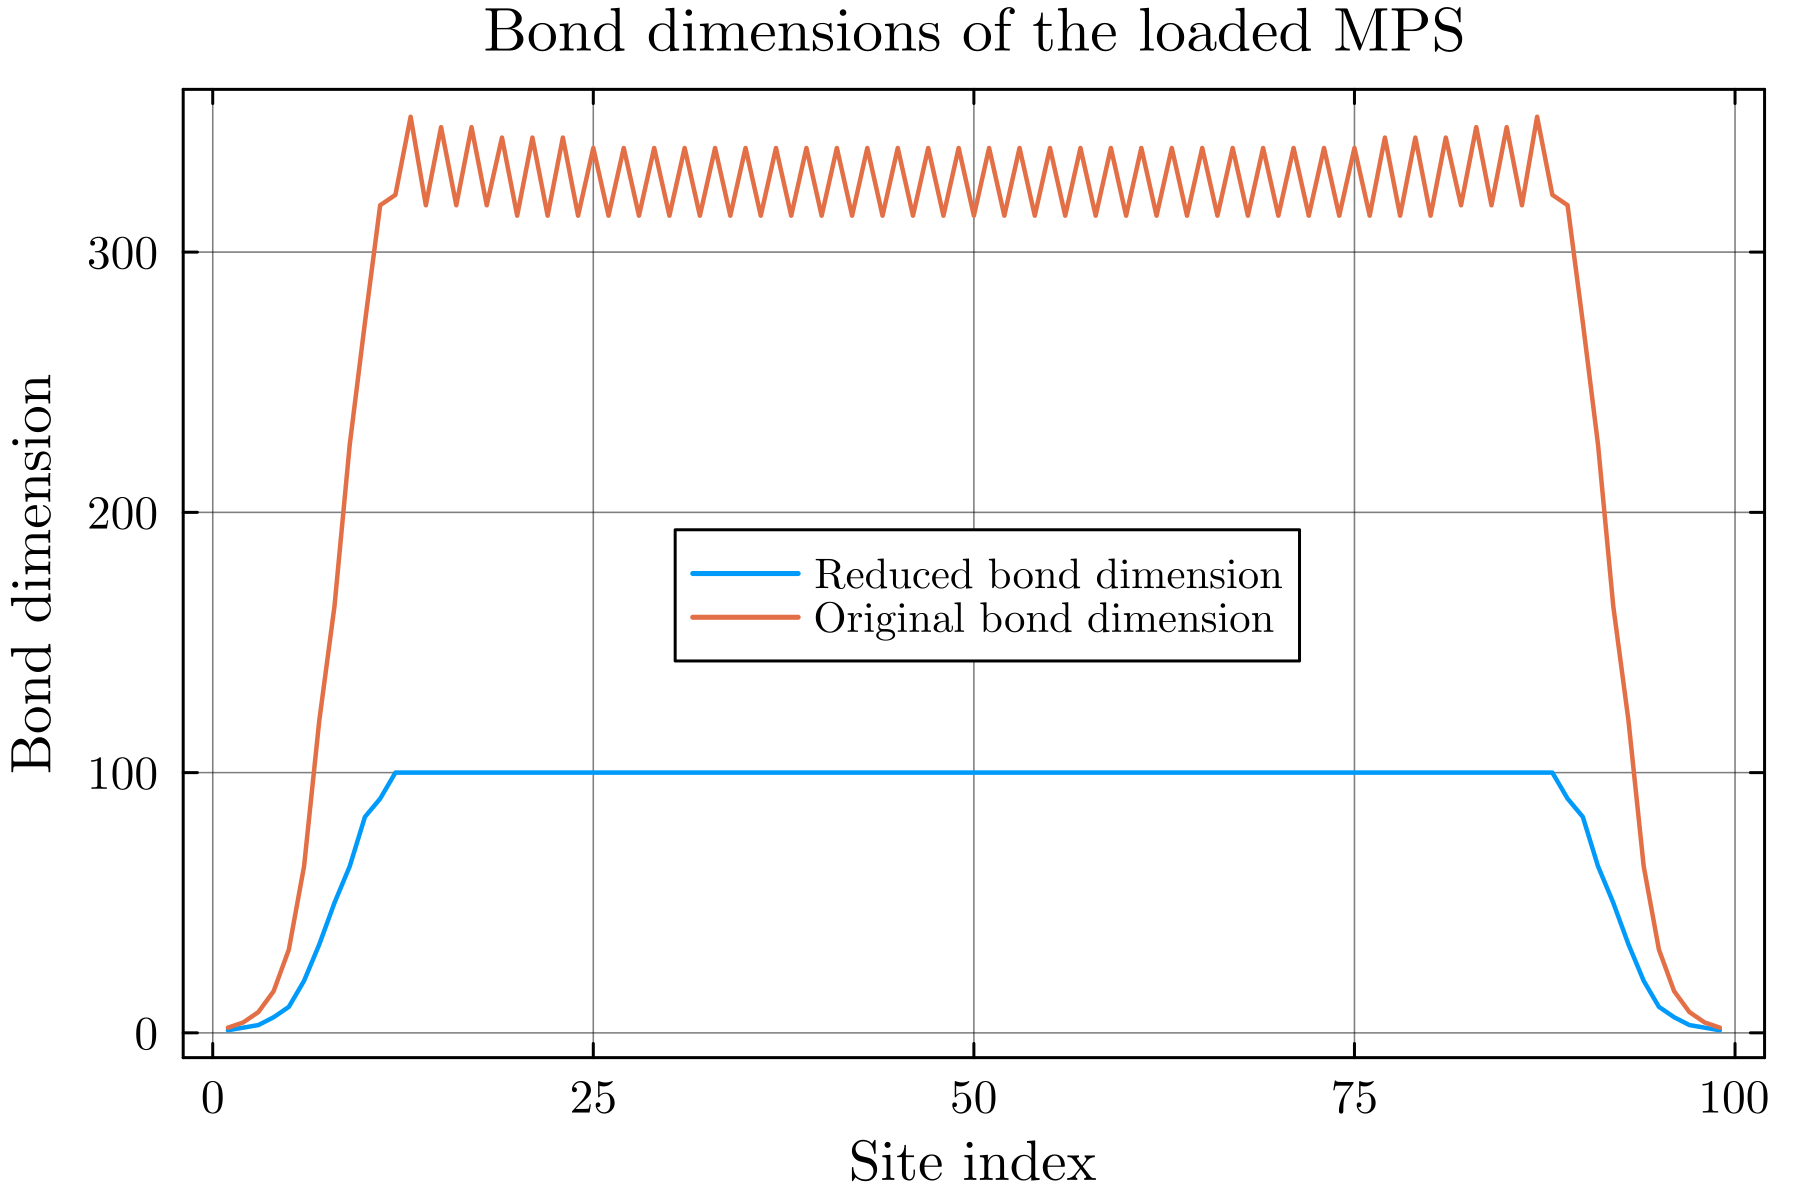

In [16]:
reduced_bd = bonddims(mps_loaded)
original_bd = bonddims(mps_loaded,full=true)

plot(reduced_bd, label="Reduced bond dimension", xlabel="Site index", ylabel="Bond dimension", title="Bond dimensions of the loaded MPS")
plot!(original_bd, label="Original bond dimension", xlabel="Site index", ylabel="Bond dimension", title="Bond dimensions of the loaded MPS",
legend=(0.4,0.5))

<span style="font-size: 20px">
Entanglement entropy can be calculated easliy by doing

In [17]:
entanglement_entropy_center= entanglement_entropy(mps_loaded,Int(length(mps_loaded)/2))

1.8902884734960232

<span style="font-size: 20px">
Finally to get expectation value or some correlators, we can use function like

In [18]:
option = SpinOptions(:SU2,1)
gls = getLocalSpace(option,("site","site","op"))


(I = 2D TLArray, 1 symmetries [SU2]  ["site+", "site-"]
  1.	1x1	| 2x2	[ 1 ; 1 ]	1.000000	√2, S = 3D TLArray, 1 symmetries [SU2]  ["site+", "site-", "op-"]
  1.	1x1x1	| 2x2x3	[ 1 ; 1 ; 2 ]	1.224745)

In [19]:
cor_mat = zeros(length(mps_loaded), length(mps_loaded))
for i = 1:length(mps_loaded)
    for j = 1:length(mps_loaded)
        println("Calculating correlation between site $i and site $j")
        cor_mat[i,j] = observe_cor(mps_loaded, gls.S, i, gls.S', j)
    end
end

Calculating correlation between site 1 and site 1
Calculating correlation between site 1 and site 2
Calculating correlation between site 1 and site 3
Calculating correlation between site 1 and site 4
Calculating correlation between site 1 and site 5
Calculating correlation between site 1 and site 6
Calculating correlation between site 1 and site 7
Calculating correlation between site 1 and site 8
Calculating correlation between site 1 and site 9


LoadError: InterruptException:

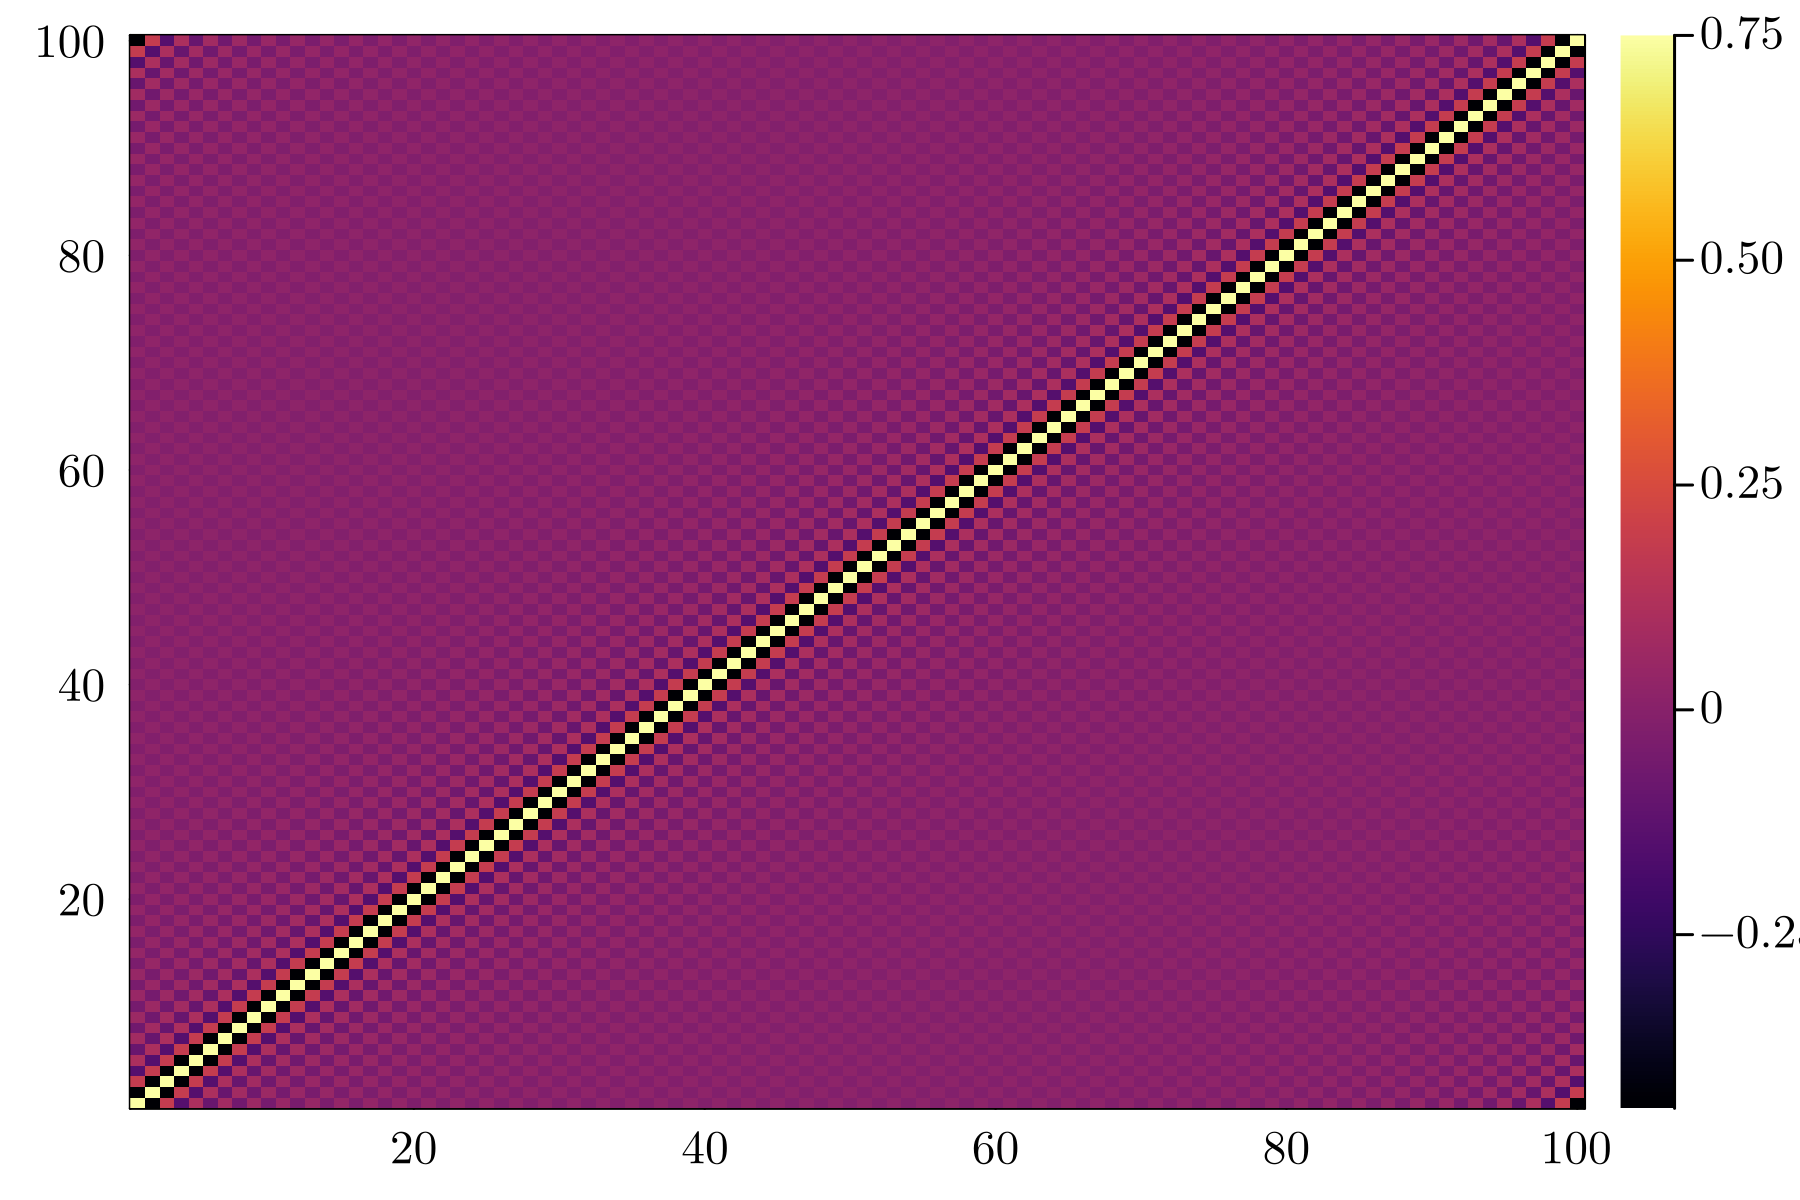

In [ ]:
heatmap(cor_mat)

# 3. move canonical site, variational fit

<span style="font-size: 20px">
from given MPS, we can check the location of orthogonal centor
<span>

In [20]:
MPS_H.oc

100

<span style="font-size: 20px">
or we can move the center by using

In [21]:
move_canonical!(MPS_H,99)

TLMps (L=100)|  center : 99
  symmetry: SU2  (1 symmetry)
  max bond dim (reduced): 100

 i,tag (D(*)|#of sectors): 100
  [  1] SLeft+ (1|1s)  1,site+ (1|1s)  1,bond,m- (1|1s)
  [  2] 1,bond,m+ (1|1s)  2,site+ (1|1s)  2,bond,m- (2|2s)
  [  3] 2,bond,m+ (2|2s)  3,site+ (1|1s)  3,bond,m- (3|2s)
  [  4] 3,bond,m+ (3|2s)  4,site+ (1|1s)  4,bond,m- (6|3s)
  ⋮
  [ 97] 96,bond,m+ (6|3s)  97,site+ (1|1s)  97,bond,m- (3|2s)
  [ 98] 97,bond,m+ (3|2s)  98,site+ (1|1s)  98,bond,m- (2|2s)
  [ 99] 98,bond,m+ (2|2s)  99,site+ (1|1s)  99,bond,m+ (1|1s)  ← oc
  [100] 99,bond,m- (1|1s)  100,site+ (1|1s)  SRight+ (1|1s)


In [31]:
Nkeeplst = [2, 4, 8, 16, 32, 64,128,256]
Elst_zipup, Elst_fit, Elst_exact = Float64[], Float64[], Float64[]
for Nkeep in Nkeeplst
    println("Calculating for Nkeep = $Nkeep")
    φ, max_dw = apply_mpo(MPO_Heisen, MPS_H; alg=:zipup, Nkeep=Nkeep)   # alg = :exact | :zipup | :fit
    push!(Elst_zipup, overlap(φ, MPS_H))
end

Calculating for Nkeep = 2
Calculating for Nkeep = 4
Calculating for Nkeep = 8
Calculating for Nkeep = 16
Calculating for Nkeep = 32
Calculating for Nkeep = 64
Calculating for Nkeep = 128
Calculating for Nkeep = 256


In [41]:
Elst_fit = Float64[]
for Nkeep in Nkeeplst
    println("Calculating for Nkeep = $Nkeep")
    φ, max_dw = apply_mpo(MPO_Heisen, MPS_H; alg=:fit, Nkeep=Nkeep,
                          max_sweeps=3,tol = 0.0, init=MPS_H)   # alg = :exact | :zipup | :fit
    push!(Elst_fit, overlap(φ, MPS_H))
end


Calculating for Nkeep = 2
Calculating for Nkeep = 4
Calculating for Nkeep = 8
Calculating for Nkeep = 16
Calculating for Nkeep = 32
Calculating for Nkeep = 64
Calculating for Nkeep = 128
Calculating for Nkeep = 256


In [34]:
for Nkeep in Nkeeplst
    println("Calculating for Nkeep = $Nkeep")
    φ, max_dw = apply_mpo(MPO_Heisen, MPS_H; alg=:exact, Nkeep=Nkeep)   # alg = :exact | :zipup | :fit
    push!(Elst_exact, overlap(φ, MPS_H))
end

Calculating for Nkeep = 2
Calculating for Nkeep = 4
Calculating for Nkeep = 8
Calculating for Nkeep = 16
Calculating for Nkeep = 32
Calculating for Nkeep = 64
Calculating for Nkeep = 128
Calculating for Nkeep = 256


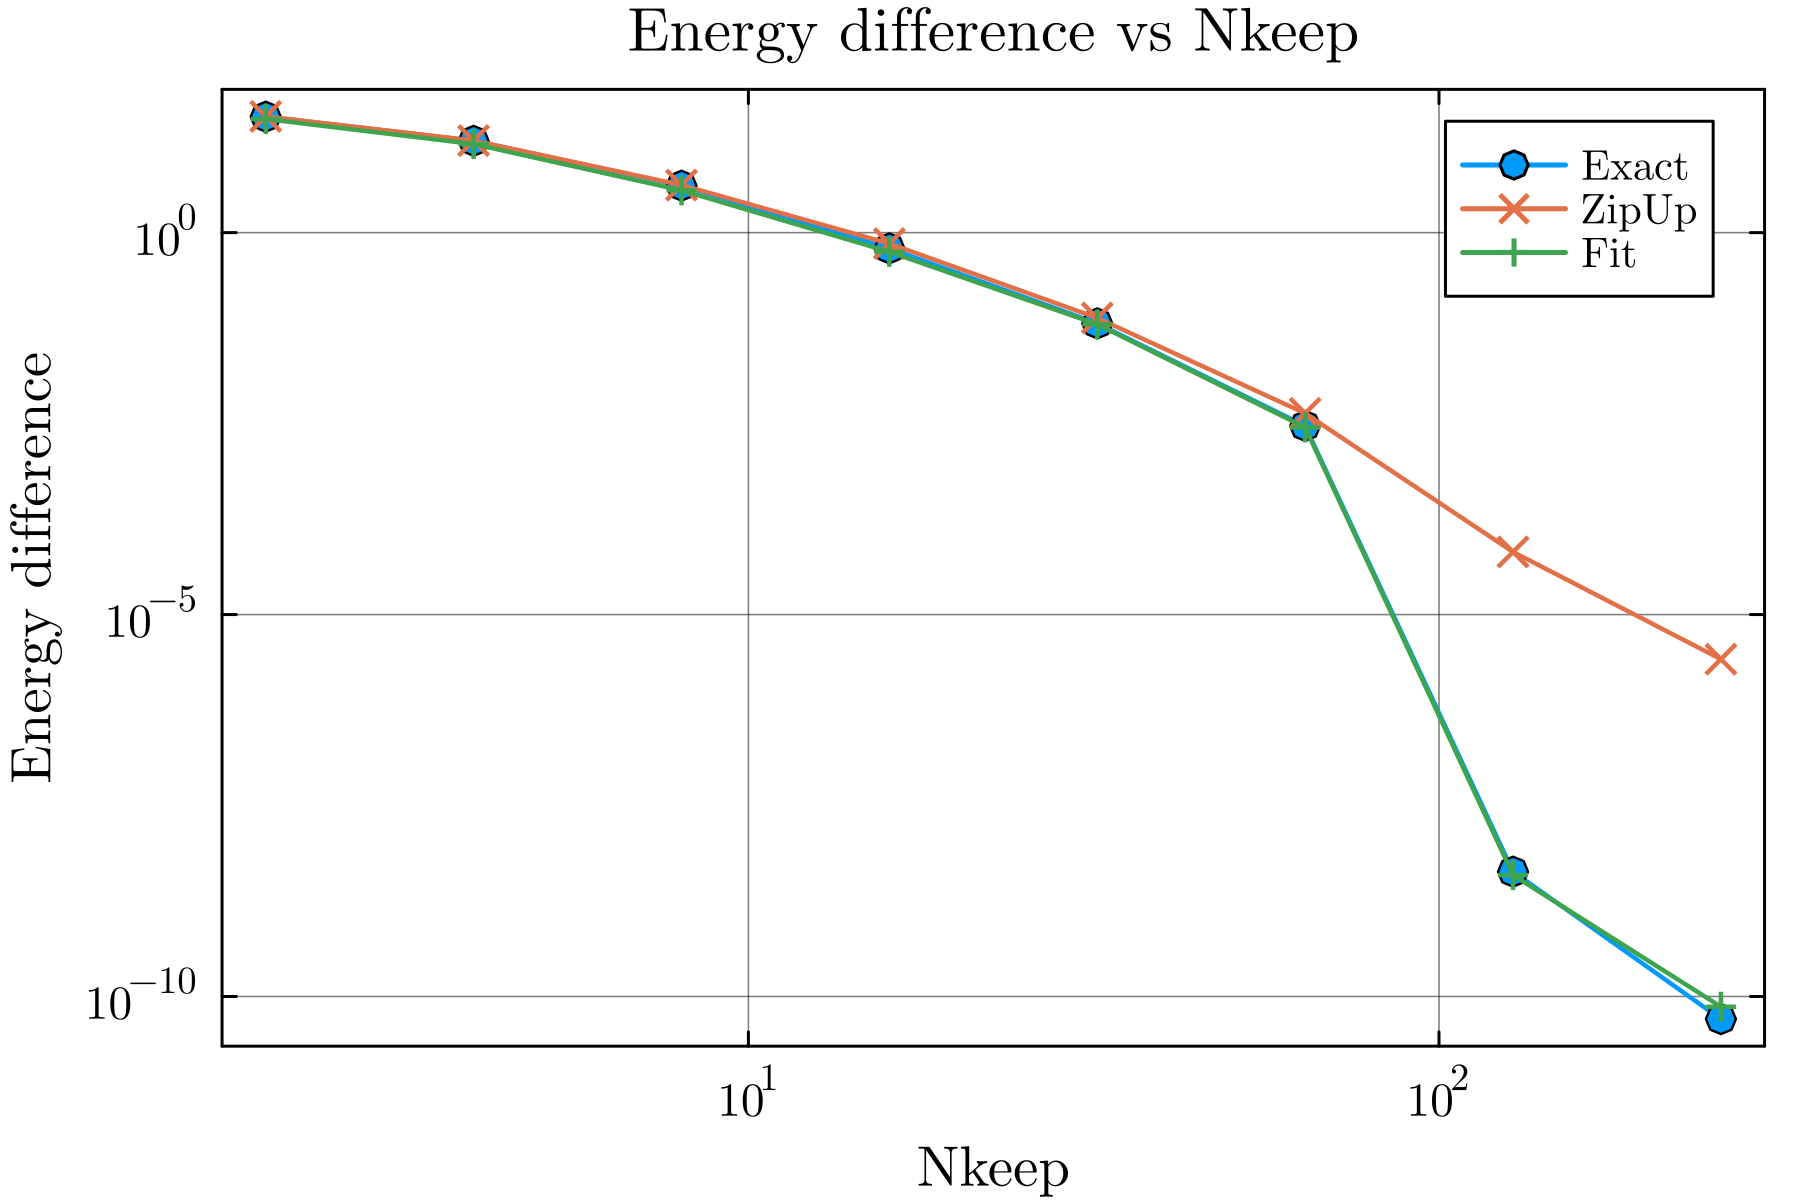

In [45]:
plot(Nkeeplst,[Elst_exact .- E_H],label="Exact",marker=:o)
plot!(Nkeeplst,[Elst_zipup .- E_H],label="ZipUp",marker=:x)
plot!(Nkeeplst,[Elst_fit .- E_H],label="Fit", xlabel="Nkeep", ylabel="Energy difference", title="Energy difference vs Nkeep",xscale=:log10, yscale=:log10,marker=:+)

